**1. Conectar con Google Cloud**


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
from google.colab import auth
auth.authenticate_user()

In [3]:
PROJECT = 'project-cd484380-6edd-4af1-8ec' # Mi proyecto de prueba
!gcloud services enable aiplatform.googleapis.com --project={PROJECT}

In [4]:
!gcloud services list --enabled --project={PROJECT} | grep aiplatform

aiplatform.googleapis.com            Agent Platform API


**2. Crear el cliente para conectar a GoogleCloud**

In [6]:
!pip install -q -U google-genai

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.


In [5]:
from google import genai

PROJECT = 'project-cd484380-6edd-4af1-8ec'
client = genai.Client(vertexai=True, project=PROJECT, location='global')

# Vemos que clientes son candidatos para ser usados. En este caso, utilizaremos 'gemini-3.5-flash'
for m in client.models.list():
    if 'gemini' in m.name.lower():
        print(m.name)

publishers/google/models/gemini-1.5-pro-002
publishers/google/models/gemini-2.5-flash-preview-04-17
publishers/google/models/gemini-2.5-pro-exp-03-25
publishers/google/models/gemini-2.5-pro
publishers/google/models/gemini-2.5-flash
publishers/google/models/gemini-2.5-flash-lite
publishers/google/models/gemini-2.5-pro-tts
publishers/google/models/gemini-2.5-flash-tts
publishers/google/models/gemini-live-2.5-flash-native-audio
publishers/google/models/gemini-3-flash-preview
publishers/google/models/gemini-3.1-flash-image-preview
publishers/google/models/gemini-3.1-pro-preview
publishers/google/models/gemini-3.5-flash
publishers/google/models/gemini-3.1-flash-image
publishers/google/models/gemini-3-pro-image
publishers/google/models/gemini-embedding-2
publishers/google/models/gemini-3.1-flash-lite
publishers/google/models/gemini-3.1-flash-lite-image
publishers/google/models/gemini-3.5-transcribe-live-preview
publishers/google/models/gemini-3.5-transcribe-preview
publishers/google/models/g

In [ ]:
candidatos = ['gemini-3.5-flash', 'gemini-3.1-flash-lite', 'gemini-3.5-flash-lite',
              'gemini-3.6-flash', 'gemini-2.5-flash-lite', 'gemini-2.5-pro']

for m in candidatos:
    try:
        r = client.models.generate_content(model=m, contents='Responde solo con la palabra: ok')
        print('OK     ', m, '->', r.text.strip())
    except Exception as e:
        print('FALLA  ', m, '->', str(e)[:90])

**3. Probar el cliente**

In [6]:
import json, time
from google.genai import types

MODELO_JUEZ = 'gemini-3.5-flash'

RUBRICA = """You are an expert physician evaluating a clinical note written from a doctor-patient conversation.
The CONVERSATION is the ground truth. The REFERENCE note is only an example of the expected style and structure.
Evaluate the CANDIDATE note. Score each criterion from 1 (very poor) to 5 (excellent):
- fidelity: every fact in the candidate is supported by the conversation. Penalize invented or distorted facts (numbers, findings, symptoms).
- completeness: the candidate includes the clinically relevant information from the conversation.
- structure: information is placed in the correct section (symptoms in HPI/ROS, exam findings in PHYSICAL EXAM, tests in RESULTS, plan in ASSESSMENT AND PLAN).
- style: professional, concise clinical language.
Also list in "invented" only facts that are NOT supported by the conversation (wrong or fabricated content). Do not list misplaced information here; that belongs to "structure". Empty list if none.
Answer ONLY with JSON: {"fidelity": int, "completeness": int, "structure": int, "style": int, "invented": [str]}"""


def juzgar(dialogo, referencia, generada, reintentos=3):
    prompt = (f"{RUBRICA}\n\nCONVERSATION:\n{dialogo}\n\nREFERENCE NOTE:\n{referencia}\n\n"
              f"CANDIDATE NOTE:\n{generada}")
    for i in range(reintentos):
        try:
            r = client.models.generate_content(
                model=MODELO_JUEZ, contents=prompt,
                config=types.GenerateContentConfig(temperature=0, response_mime_type='application/json'))
            res = json.loads(r.text)
            u = r.usage_metadata
            res['tok_in'] = u.prompt_token_count
            res['tok_out'] = u.total_token_count - u.prompt_token_count
            return res
        except Exception as e:
            print('Reintento por error:', str(e)[:80])
            time.sleep(5)
    return None

In [8]:
# Probamos 3 notas

import pandas as pd
BASE = '/content/drive/MyDrive/Proyecto_Final_IA'
CARPETA = f'{BASE}/P2_Comparacion'
train = pd.read_csv(f'{BASE}/Dataset/challenge_data/train.csv')
dialogos = dict(zip(train['encounter_id'], train['dialogue']))

df = pd.read_csv(f'{CARPETA}/QWEN257b.csv')
for _, f in df.head(3).iterrows():
    res = juzgar(dialogos[f['encounter_id']], f['nota_referencia'], f['nota_generada'])
    print(f['encounter_id'], res)

D2N001 {'fidelity': 5, 'completeness': 4, 'structure': 3, 'style': 5, 'invented': [], 'tok_in': 3361, 'tok_out': 1144}
D2N002 {'fidelity': 5, 'completeness': 4, 'structure': 3, 'style': 5, 'invented': [], 'tok_in': 3065, 'tok_out': 1200}
D2N003 {'fidelity': 5, 'completeness': 4, 'structure': 4, 'style': 5, 'invented': [], 'tok_in': 2935, 'tok_out': 1526}


**4. Generamos las métricas**

In [10]:
import glob, os
import pandas as pd

JUEZ_DIR = f'{BASE}/P3_LLM_as_Judge'
os.makedirs(JUEZ_DIR, exist_ok=True)

archivos = sorted(a for a in glob.glob(f'{CARPETA}/*.csv')
                  if not os.path.basename(a).startswith('metricas_'))
print([os.path.basename(a) for a in archivos])

for ruta in archivos:
    modelo = os.path.basename(ruta).replace('.csv', '')
    destino = f'{JUEZ_DIR}/juez_{modelo}.csv'
    df = pd.read_csv(ruta)
    filas = pd.read_csv(destino).to_dict('records') if os.path.exists(destino) else []
    hechos = {f['encounter_id'] for f in filas}

    for _, f in df.iterrows():
        if f['encounter_id'] in hechos:
            continue
        res = juzgar(dialogos[f['encounter_id']], f['nota_referencia'], f['nota_generada'])
        if res is None:
            continue
        res['invented_n'] = len(res.pop('invented', []))
        res['encounter_id'] = f['encounter_id']
        filas.append(res)
        if len(filas) % 5 == 0:
            pd.DataFrame(filas).to_csv(destino, index=False)
            print(f'{modelo}: {len(filas)}/{len(df)}')
    pd.DataFrame(filas).to_csv(destino, index=False)
    print(f'{modelo} terminado: {len(filas)}/{len(df)} notas juzgadas')

['MISTRAL7b.csv', 'PHI35mini.csv', 'QWEN253b.csv', 'QWEN257b.csv']
MISTRAL7b terminado: 67/67 notas juzgadas
PHI35mini terminado: 67/67 notas juzgadas
QWEN253b terminado: 67/67 notas juzgadas
QWEN257b terminado: 67/67 notas juzgadas


**5. Comparativa de LLM**

In [11]:
# Tabla

cols = ['fidelity', 'completeness', 'structure', 'style', 'invented_n']
juez = {os.path.basename(a).replace('.csv', ''): pd.read_csv(f"{JUEZ_DIR}/juez_{os.path.basename(a)}")
        for a in archivos}
tabla_juez = pd.DataFrame({m: d[cols].mean() for m, d in juez.items()}).T
print(tabla_juez.round(2))
print('Tokens entrada:', sum(d['tok_in'].sum() for d in juez.values()),
      '| salida:', sum(d['tok_out'].sum() for d in juez.values()))

           fidelity  completeness  structure  style  invented_n
MISTRAL7b      3.64          3.84       4.18   4.58        2.19
PHI35mini      3.60          3.97       3.85   4.28        2.07
QWEN253b       2.64          3.33       3.19   3.54        4.67
QWEN257b       3.73          3.97       3.09   4.42        2.15
Tokens entrada: 779849 | salida: 637347


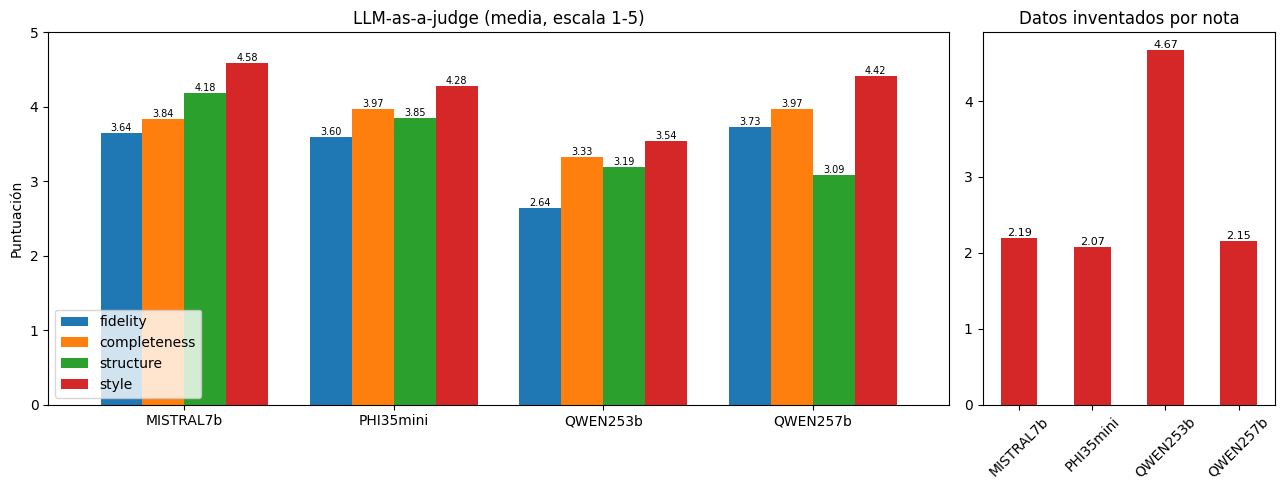

In [12]:
# Grafica

import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [4, 1.3]})

tabla_juez[['fidelity', 'completeness', 'structure', 'style']].plot(kind='bar', ax=axs[0], width=0.8)
axs[0].set_title('LLM-as-a-judge (media, escala 1-5)')
axs[0].set_ylim(0, 5)
axs[0].set_ylabel('Puntuación')
axs[0].tick_params(axis='x', rotation=0)
for c in axs[0].containers:
    axs[0].bar_label(c, fmt='%.2f', fontsize=7)

tabla_juez['invented_n'].plot(kind='bar', ax=axs[1], color='tab:red')
axs[1].set_title('Datos inventados por nota')
axs[1].tick_params(axis='x', rotation=45)
axs[1].bar_label(axs[1].containers[0], fmt='%.2f', fontsize=8)

plt.tight_layout()
plt.savefig(f'{JUEZ_DIR}/comparacion_juez.png', dpi=150)
plt.show()

**6. Generar las notas con gemini**

In [15]:
import time, os
import pandas as pd
from google.genai import types

SYSTEM = """You are a medical scribe. Write a clinical note from a doctor-patient conversation.

Use these section headings, in uppercase, in this order:
CHIEF COMPLAINT
HISTORY OF PRESENT ILLNESS
REVIEW OF SYSTEMS
PHYSICAL EXAM
RESULTS
ASSESSMENT AND PLAN

Section rules:
- CHIEF COMPLAINT: the reason for the visit in a few words (e.g. "Annual exam."). Always include it.
- HISTORY OF PRESENT ILLNESS: start with age, sex and relevant past medical history, then the symptoms, habits, medication adherence and concerns the patient reports.
- REVIEW OF SYSTEMS: bullet list by system ("• System: finding."), only for symptoms the patient reports or denies in the conversation (symptoms only, never exam findings or test results). Do NOT list systems that were not discussed.
- PHYSICAL EXAM: only findings that the doctor explicitly states during the exam. Do not add normal findings or vital sign values that are not mentioned.
- RESULTS: only lab, imaging or test results (e.g. echocardiogram, lipid panel).
- ASSESSMENT AND PLAN: one short assessment sentence, then the plan for each problem.

General rules:
- Third person, professional clinical language.
- Use only information stated in the conversation. Never invent findings or add phrases like "no other abnormalities".
- Never fill in typical or normal findings. If it was not said in the conversation, do not write it.
- Copy specific details exactly as stated (grades, doses, numbers, frequencies). Do not generalize them.
- The doctor may mention symptoms from an intake form (e.g. "you were endorsing nasal congestion"). Include them in the HPI and REVIEW OF SYSTEMS.
- Include every test or follow-up the doctor orders or plans to repeat in ASSESSMENT AND PLAN.
- If a section has no information (except CHIEF COMPLAINT), omit it.
- Do not add any text before or after the note."""

MODELO_GEN = 'gemini-3.6-flash'

def generar_nota_gemini(dialogo, reintentos=6):
    user = f"Conversation:\n\n{dialogo}\n\nWrite the clinical note."
    for i in range(reintentos):
        try:
            r = client.models.generate_content(
                model=MODELO_GEN, contents=user,
                config=types.GenerateContentConfig(
                    system_instruction=SYSTEM, temperature=0, max_output_tokens=4096))
            return r.text
        except Exception as e:
            print('Reintento por error:', str(e)[:80])
            time.sleep(10 * (i + 1))
    return None

In [16]:
# Probar una nota

train = pd.read_csv(f'{BASE}/Dataset/challenge_data/train.csv')
print(generar_nota_gemini(train.iloc[0]['dialogue']))

CHIEF COMPLAINT
Annual exam.

HISTORY OF PRESENT ILLNESS
Martha is a 50-year-old female with a past medical history of congestive heart failure, depression, and hypertension who presents for her annual exam. She reports doing well, traveling, and staying active with hiking. 

Regarding her congestive heart failure, she reports complying with a low-sodium diet, avoiding salty foods such as tater tots and soft pretzels, and taking her medications. She denies chest pain, shortness of breath, and leg swelling.

Regarding her depression, she has been attending weekly therapy over the past year since her last annual exam, which she finds very helpful. She denies feelings of wanting to harm herself or hurt others. 

Regarding her hypertension, she reports continuing to forget to take her blood pressure medication. She notes that her blood pressure increases when work is stressful, reporting long hours, late nights, and significant responsibility related to pulling fiscal year-end data. 

On t

In [17]:
# Todas las notas

destino = f'{CARPETA}/GEMINI36flash.csv'
filas = pd.read_csv(destino).to_dict('records') if os.path.exists(destino) else []
hechos = {f['encounter_id'] for f in filas}

for _, f in train.iterrows():
    if f['encounter_id'] in hechos:
        continue
    nota = generar_nota_gemini(f['dialogue'])
    if nota is None:
        continue
    filas.append({'encounter_id': f['encounter_id'],
                  'nota_generada': nota,
                  'nota_referencia': f['note']})
    time.sleep(1.5)
    if len(filas) % 5 == 0:
        pd.DataFrame(filas).to_csv(destino, index=False)
        print(f'{len(filas)}/{len(train)}')

pd.DataFrame(filas).to_csv(destino, index=False)
print(f'Terminado: {len(filas)}/{len(train)}')

5/67
10/67
15/67
20/67
25/67
30/67
35/67
40/67
45/67
50/67
55/67
60/67
65/67
Terminado: 67/67
